<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🔬 Research agent：手搓 ReAct 循环、两层压缩、搜索预算

**一句话定位**：研究是开放任务，策略事先不可知，所以用 agent；但 agent 会**搜不停**和**context 爆炸**，本节的全部技巧都在治这两件事：prompt 预算 + `think_tool` 治前者，网页摘要 + 轨迹压缩治后者。
> 对应主课 `2_a_🔥_research_agent.ipynb`；langchain-core 1.4 核对 `@tool(parse_docstring=True)` / `InjectedToolArg` 未变。

</div>

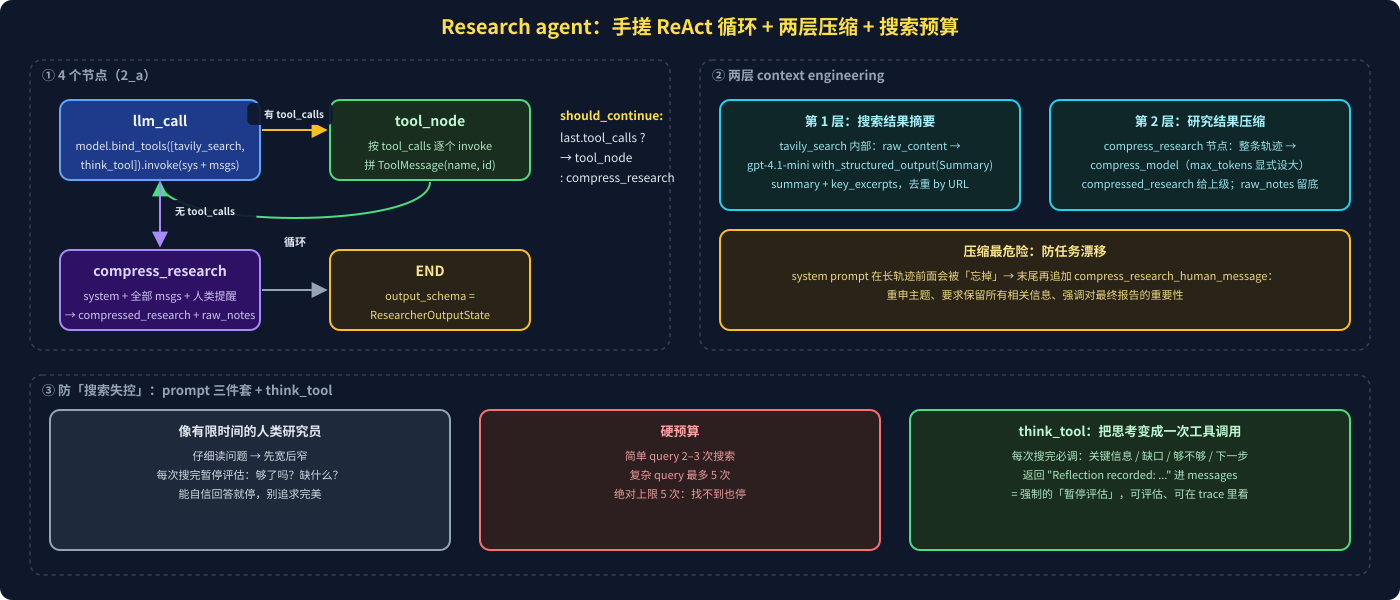

In [ ]:
from IPython.display import SVG
SVG(filename="assets/02_research_loop.svg")

### 1️⃣ 手搓循环的三段代码

In [ ]:
from langgraph.graph import StateGraph, START, END

tools = [tavily_search, think_tool]
tools_by_name = {t.name: t for t in tools}
model_with_tools = model.bind_tools(tools)                     # 工具 schema 进模型

def llm_call(state):
    return {"researcher_messages": [model_with_tools.invoke([SystemMessage(research_agent_prompt)] + state["researcher_messages"])]}

def tool_node(state):
    calls = state["researcher_messages"][-1].tool_calls
    outs = [tools_by_name[c["name"]].invoke(c["args"]) for c in calls]          # 顺序执行；ToolNode 会并发
    return {"researcher_messages": [ToolMessage(content=o, name=c["name"], tool_call_id=c["id"]) for o, c in zip(outs, calls)]}

def should_continue(state):
    return "tool_node" if state["researcher_messages"][-1].tool_calls else "compress_research"

b = StateGraph(ResearcherState, output_schema=ResearcherOutputState)          # 对外只暴露 compressed_research / raw_notes
b.add_node("llm_call", llm_call); b.add_node("tool_node", tool_node); b.add_node("compress_research", compress_research)
b.add_edge(START, "llm_call")
b.add_conditional_edges("llm_call", should_continue, {"tool_node": "tool_node", "compress_research": "compress_research"})
b.add_edge("tool_node", "llm_call"); b.add_edge("compress_research", END)
researcher_agent = b.compile()

| 零件 | 等价物（1.x） |
|---|---|
| `llm_call` + `bind_tools` | `create_agent` / `create_deep_agent` 内置 model 节点 |
| 手写 `tool_node` | `langgraph.prebuilt.ToolNode`：并发执行、异常 → `ToolMessage(status="error")` |
| `should_continue` | 内置「无 tool_calls 即停」 |
| `compress_research` 挂在 END 前 | 无直接等价；deepagents 的做法是**子代理只把最终消息回传父代理** |
| `output_schema=ResearcherOutputState` | 同样可用；子图嵌入时只有这些 key 会流回父图 |

### 2️⃣ 工具：`@tool(parse_docstring=True)` + `InjectedToolArg`

In [ ]:
from typing_extensions import Annotated, Literal
from langchain_core.tools import tool, InjectedToolArg

@tool(parse_docstring=True)                                    # Google 风格 docstring 的 Args 段 → 每个参数的 description
def tavily_search(
    query: str,
    max_results: Annotated[int, InjectedToolArg] = 3,          # 不进模型 schema；调用时由代码传或用默认值
    topic: Annotated[Literal["general", "news", "finance"], InjectedToolArg] = "general",
) -> str:
    """Fetch results from Tavily search API with content summarization.

    Args:
        query: A single search query to execute
        max_results: Maximum number of results to return
        topic: Topic to filter results by ('general', 'news', 'finance')
    """
    ...

@tool(parse_docstring=True)
def think_tool(reflection: str) -> str:
    """Tool for strategic reflection on research progress and decision-making. ..."""
    return f"Reflection recorded: {reflection}"                 # 什么都不做，价值在于逼模型停下来写分析

`tavily_search` 内部四步：`tavily_client.search(include_raw_content=True)` → 按 URL 去重 → 每页 `gpt-4.1-mini` 做 `Summary(summary, key_excerpts)` → 拼成 `--- SOURCE i: title --- URL ... SUMMARY ...`。摘要失败就截前 1000 字兜底。
`InjectedToolArg` 在 1.x 仍可用；`create_agent` / deepagents 另有 `runtime: ToolRuntime`（拿 state / store / tool_call_id），手搓 `tool_node` 不会注入它。

### 3️⃣ 评估「该停还是该继续」

| 做法 | 细节 |
|---|---|
| dataset | 两条手工构造的 messages 轨迹：一条搜索结果泛泛（应继续），一条已有 Coffee Review 分数等硬信息（应停） |
| target | **只跑一个节点**：`researcher_agent.nodes["llm_call"].invoke(inputs)` —— 不用跑整个图 |
| evaluator | 硬规则：最后一条 AIMessage 有 `tool_calls` ⇔ 判为 continue，与 `reference_outputs["next_step"]` 比对 |

两种失败模式：**早停**（答案太浅）和**死循环**（token 浪费 + context rot）。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**🆕 2026-10 对照**

- 模型已是 `claude-sonnet-4-6`（上游 2026-06 改）；当前 Anthropic 为 Claude 5 系列，换模型只改字符串。课程里的 output token 上限表和 99s/38s 延迟对比是 2025-07 的旧型号数据，**「压缩节点显式设 `max_tokens`、可换便宜模型」的原则不变**。
- 官方 2026 deepagents deep research 例子**原样沿用** `think_tool` 和「简单 2–3 次 / 复杂 5 次」预算 —— 这一节的 prompt 设计是整门课最保值的部分。

</div>

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| 工具函数抛异常 | 手搓 `tool_node` 没 try/except → 整个 invoke 中断；`ToolNode` 会转成错误 ToolMessage |
| `compress_model` 没设 `max_tokens` | 长报告被截断（"Sextant Coffee Ro…"） |
| 压缩 prompt 只放 system | 长轨迹后模型忘任务 → 泛泛而谈；末尾再加一条 HumanMessage 重申 |
| `tool_node` 里用 `tool.invoke` 调 MCP 工具 | MCP 工具只有 async 实现，要 `ainvoke`（3_a） |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：research agent = **`bind_tools` + 手写 tool 循环 + `compress_research` 收尾**；治搜不停靠 **prompt 预算 + `think_tool`**，治 context 爆炸靠 **网页摘要 + 轨迹压缩（末尾重申任务）**；评估只测 `llm_call` 一个节点的「停 / 继续」决策。

</div>